In [ ]:
'''Для выполнения домашнего задания я использую датасет customer_churn_features.csv, который был подготовлен в рамках первой промежуточной аттестации.
В качестве целевой переменной я буду использовать churn, которая показывает наличие или отсутствие оттока клиента.
Это позволит  продолжить исследование банковских клиентов и сравнить несколько ансамблевых методов классификации.'''

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("customer_churn_features.csv")

print("Размер датасета:", df.shape)

display(df.head())

print("\nРаспределение целевой переменной:")
print(df["churn"].value_counts())

print("\nДоля классов:")
print(df["churn"].value_counts(normalize=True).round(4))

Saving customer_churn_features.csv to customer_churn_features (1).csv
Размер датасета: (10000, 22)


,customer_id,age,gender,registration_date,annual_income,account_count,active_account_count,card_count,active_card_count,transaction_count,...,card_purchase_count,atm_withdrawal_count,transfer_out_count,utility_payment_count,transfer_count,loan_count,total_loan_amount,avg_interest_rate,last_transaction_date,churn
0,1,34,M,2025-07-12,455276.04,1,1,1,1,266,...,249,5,0,0,0,0,0.0,0.0,2026-01-27,0
1,2,54,M,2025-03-22,1945830.96,2,2,1,1,465,...,434,9,0,4,0,0,0.0,0.0,2026-01-26,0
2,3,18,F,2025-10-01,315794.16,1,1,1,1,155,...,144,2,1,1,1,0,0.0,0.0,2026-01-27,0
3,4,18,F,2025-11-22,647645.88,2,2,1,1,76,...,70,2,0,2,0,0,0.0,0.0,2026-01-25,0
4,5,49,M,2025-09-30,1061109.84,2,2,0,0,165,...,153,2,0,3,0,0,0.0,0.0,2026-01-27,0



Распределение целевой переменной:
churn
0    9303
1     697
Name: count, dtype: int64

Доля классов:
churn
0    0.9303
1    0.0697
Name: proportion, dtype: float64


In [ ]:
'''классы несбалансированы. Ушедшие клиенты составляют всего 6,97% выборки. Поэтому при оценке моделей я буду смотреть
не только на accuracy, но и на precision, recall, F1 и ROC-AUC. Особенно важно не пропускать клиентов, которые могут уйти.
Я оставлю признаки, которые характеризуют возраст, доход, использование счетов, карт, транзакционную активность и кредитные продукты.
customer_id исключаю, поскольку это только идентификатор клиента. Даты пока тоже исключаю, чтобы не усложнять подготовку данных.
Целевой переменной остается churn.'''

In [3]:
# Выбираю признаки для обучения моделей

features = [
    "age",
    "gender",
    "annual_income",
    "account_count",
    "active_account_count",
    "card_count",
    "active_card_count",
    "transaction_count",
    "total_transaction_amount",
    "avg_transaction_amount",
    "card_purchase_count",
    "atm_withdrawal_count",
    "transfer_out_count",
    "utility_payment_count",
    "transfer_count",
    "loan_count",
    "total_loan_amount",
    "avg_interest_rate"
]

X = df[features].copy()
y = df["churn"].copy()

# Преобразую категориальный признак gender в числовой формат
X = pd.get_dummies(X, columns=["gender"], drop_first=True, dtype=int)

print("Размер матрицы признаков:", X.shape)
print("Размер целевой переменной:", y.shape)

print("\nПропущенные значения:")
print(X.isnull().sum().sum())

print("\nЦелевая переменная:")
print(y.value_counts())

Размер матрицы признаков: (10000, 18)
Размер целевой переменной: (10000,)

Пропущенные значения:
0

Целевая переменная:
churn
0    9303
1     697
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

# Сначала отделяю 20% данных для тестовой выборки
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Из оставшихся 80% выделяю 25% для валидации
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("Обучающая выборка:", X_train.shape)
print("Валидационная выборка:", X_val.shape)
print("Тестовая выборка:", X_test.shape)

print("\nДоля оттока в выборках:")
print("Обучающая:", round(y_train.mean() * 100, 2), "%")
print("Валидационная:", round(y_val.mean() * 100, 2), "%")
print("Тестовая:", round(y_test.mean() * 100, 2), "%")

Обучающая выборка: (6000, 18)
Валидационная выборка: (2000, 18)
Тестовая выборка: (2000, 18)

Доля оттока в выборках:
Обучающая: 6.98 %
Валидационная: 6.95 %
Тестовая: 6.95 %


In [ ]:
'''Перед обучением ансамблевых алгоритмов я решила построить две базовые модели: логистическую регрессию и дерево решений.
Они позволят получить начальные результаты классификации и в дальнейшем оценить, насколько ансамблевые методы улучшают качество предсказаний.
Для оценки моделей я буду использовать несколько метрик, поскольку в исходных данных наблюдается дисбаланс классов.'''

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Функция для оценки моделей
def evaluate_model(model, X_val, y_val):
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    return {
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    }

# Логистическая регрессия
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

log_reg.fit(X_train, y_train)

# Дерево решений
tree = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

tree.fit(X_train, y_train)

# Оценка моделей
baseline_results = pd.DataFrame({
    "Logistic Regression": evaluate_model(log_reg, X_val, y_val),
    "Decision Tree": evaluate_model(tree, X_val, y_val)
}).T

display(baseline_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.491,0.0627,0.4532,0.1101,0.4862
Decision Tree,0.865,0.0774,0.0863,0.0816,0.5047


In [ ]:
'''Логистическая регрессия лучше определяет клиентов, склонных к оттоку: ее Recall составляет
0.4532, а F1 — 0.1101. Дерево решений показывает более высокую Accuracy, но значительно хуже находит клиентов
с оттоком. Результаты обеих моделей пока невысокие, поэтому я решила проверить, смогут ли ансамблевые методы улучшить качество классификации.
Сначала обучу две ансамблевые модели: Bagging и Random Forest. Для подбора параметров буду использовать GridSearchCV с кросс-валидацией.
Я обучу модели BaggingClassifier и RandomForestClassifier и подберу для них оптимальные параметры с помощью GridSearchCV.
В качестве основной метрики для подбора выберу F1, поскольку мне важно не только правильно классифицировать большинство клиентов,
но и находить клиентов, которые ушли.'''

In [6]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Bagging
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(class_weight="balanced"),
    random_state=42,
    n_jobs=-1
)

bagging_params = {
    "n_estimators": [50, 100],
    "max_samples": [0.7, 1.0],
    "max_features": [0.7, 1.0]
}

bagging_grid = GridSearchCV(
    bagging,
    bagging_params,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

bagging_grid.fit(X_train, y_train)

# Random Forest
rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [2, 5]
}

rf_grid = GridSearchCV(
    rf,
    rf_params,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

# Оценка на validation
ensemble_results = pd.DataFrame({
    "Bagging": evaluate_model(
        bagging_grid.best_estimator_, X_val, y_val
    ),
    "Random Forest": evaluate_model(
        rf_grid.best_estimator_, X_val, y_val
    )
}).T

print("Лучшие параметры Bagging:", bagging_grid.best_params_)
print("Лучшие параметры Random Forest:", rf_grid.best_params_)

display(ensemble_results.round(4))

Лучшие параметры Bagging: {'max_features': 0.7, 'max_samples': 0.7, 'n_estimators': 50}
Лучшие параметры Random Forest: {'max_depth': 5, 'min_samples_leaf': 2, 'n_estimators': 100}


,Accuracy,Precision,Recall,F1,ROC-AUC
Bagging,0.9305,0.0000,0.0000,0.0000,0.4655
Random Forest,0.7630,0.0557,0.1511,0.0814,0.4710


In [ ]:
'''Bagging показал высокую Accuracy, но не смог правильно определить ни одного клиента с оттоком.
Random Forest обнаружил часть таких клиентов, однако его F1 оказался ниже, чем у логистической регрессии.
Пока ансамбли не показали улучшения качества, поэтому я решила проверить модель Stacking, которая объединяет предсказания нескольких алгоритмов.
Шаг 6. StackingClassifier
Markdown-ячейка:

Для следующего эксперимента я использую StackingClassifier.
Эта модель объединяет логистическую регрессию и дерево решений, а итоговое предсказание формирует
с помощью дополнительной логистической регрессии.'''

In [7]:
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

stacking = StackingClassifier(
    estimators=[
        ("tree", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        )),
        ("logistic", make_pipeline(
            StandardScaler(),
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=42
            )
        ))
    ],
    final_estimator=LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),
    cv=3,
    n_jobs=-1
)

stacking_params = {
    "final_estimator__C": [0.1, 1, 10]
}

stacking_grid = GridSearchCV(
    stacking,
    stacking_params,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

stacking_grid.fit(X_train, y_train)

stacking_results = pd.DataFrame({
    "Stacking": evaluate_model(
        stacking_grid.best_estimator_, X_val, y_val
    )
}).T

print("Лучшие параметры Stacking:", stacking_grid.best_params_)
display(stacking_results.round(4))

Лучшие параметры Stacking: {'final_estimator__C': 1}


,Accuracy,Precision,Recall,F1,ROC-AUC
Stacking,0.545,0.0768,0.5036,0.1333,0.5205


In [ ]:
'''Stacking показал лучший результат среди проверенных моделей: F1 составил
0.1333, Recall — 0.5036, ROC-AUC — 0.5205. Модель находит примерно половину клиентов с оттоком,
но точность предсказаний остается низкой. Я решила проверить, смогут ли модели градиентного бустинга улучшить эти результаты.

На следующем этапе я обучу GradientBoostingClassifier. Подберу количество деревьев,
скорость обучения и глубину деревьев с помощью GridSearchCV. Затем оценю модель на валидационной выборке.'''

In [8]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

gb = GradientBoostingClassifier(random_state=42)

gb_params = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
    "subsample": [0.8, 1.0]
}

gb_grid = GridSearchCV(
    gb,
    gb_params,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

gb_results = pd.DataFrame({
    "Gradient Boosting": evaluate_model(
        gb_grid.best_estimator_, X_val, y_val
    )
}).T

print("Лучшие параметры Gradient Boosting:", gb_grid.best_params_)
display(gb_results.round(4))

Лучшие параметры Gradient Boosting: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50, 'subsample': 1.0}


,Accuracy,Precision,Recall,F1,ROC-AUC
Gradient Boosting,0.9295,0.0,0.0,0.0,0.4622


In [ ]:
'''Gradient Boosting не смог определить клиентов с оттоком: Recall и F1 равны нулю.
Несмотря на высокую Accuracy, модель не подходит для нашей задачи. Пока лучший результат остается у Stacking.
Сначала установим библиотеку.

Я решила проверить модель LightGBM, которая использует градиентный бустинг на деревьях решений.
Подберу ее основные параметры и сравню качество с предыдущими моделями.'''

In [9]:
!pip install lightgbm -q

In [10]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV

lgbm = LGBMClassifier(
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_params = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [-1, 5],
    "num_leaves": [15, 31]
}

lgbm_grid = GridSearchCV(
    lgbm,
    lgbm_params,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

lgbm_grid.fit(X_train, y_train)

lgbm_results = pd.DataFrame({
    "LightGBM": evaluate_model(
        lgbm_grid.best_estimator_, X_val, y_val
    )
}).T

print("Лучшие параметры LightGBM:", lgbm_grid.best_params_)
display(lgbm_results.round(4))

Лучшие параметры LightGBM: {'learning_rate': 0.1, 'max_depth': -1, 'n_estimators': 50, 'num_leaves': 31}


,Accuracy,Precision,Recall,F1,ROC-AUC
LightGBM,0.777,0.0525,0.1295,0.0747,0.4682


In [ ]:
'''LightGBM показал низкие результаты: F1 составил 0.0747, Recall — 0.1295.
Модель уступает Stacking и логистической регрессии по основным метрикам.
Поэтому я продолжу проверку других алгоритмов градиентного бустинга.

На этом этапе я обучу модель XGBoost и подберу ее гиперпараметры с помощью GridSearchCV.
Для учета дисбаланса классов использую параметр scale_pos_weight.'''

In [11]:
!pip install xgboost -q

In [12]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

xgb = XGBClassifier(
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

xgb_params = {
    "n_estimators": [50, 100],
    "max_depth": [2, 3],
    "learning_rate": [0.05, 0.1]
}

xgb_grid = GridSearchCV(
    xgb,
    xgb_params,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

xgb_results = pd.DataFrame({
    "XGBoost": evaluate_model(
        xgb_grid.best_estimator_, X_val, y_val
    )
}).T

print("Лучшие параметры XGBoost:", xgb_grid.best_params_)
display(xgb_results.round(4))

Лучшие параметры XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}


,Accuracy,Precision,Recall,F1,ROC-AUC
XGBoost,0.6105,0.064,0.3381,0.1077,0.4644


In [ ]:
'''XGBoost показал Recall 0.3381 и F1 0.1077. Результат немного уступает Stacking,
но модель находит больше клиентов с оттоком, чем некоторые предыдущие ансамбли.
Теперь осталось проверить последнюю модель — CatBoost.
На заключительном этапе обучения ансамблей я проверю CatBoostClassifier.
Подберу основные гиперпараметры с помощью GridSearchCV и оценю качество модели на валидационной выборке.'''

In [13]:
!pip install catboost -q

In [14]:
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV

catboost = CatBoostClassifier(
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
    thread_count=1
)

catboost_params = {
    "iterations": [50, 100],
    "depth": [4, 6],
    "learning_rate": [0.05, 0.1]
}

catboost_grid = GridSearchCV(
    catboost,
    catboost_params,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

catboost_grid.fit(X_train, y_train)

catboost_results = pd.DataFrame({
    "CatBoost": evaluate_model(
        catboost_grid.best_estimator_, X_val, y_val
    )
}).T

print("Лучшие параметры CatBoost:", catboost_grid.best_params_)
display(catboost_results.round(4))

Лучшие параметры CatBoost: {'depth': 6, 'iterations': 50, 'learning_rate': 0.1}


,Accuracy,Precision,Recall,F1,ROC-AUC
CatBoost,0.654,0.0646,0.295,0.1059,0.4827


In [ ]:
'''Я собрала результаты всех моделей, чтобы сравнить их качество на валидационной выборке.
Основное внимание уделяю F1, Recall и ROC-AUC, так как классы в исходных данных распределены неравномерно.'''

In [15]:
all_results = pd.concat([
    baseline_results,
    ensemble_results,
    stacking_results,
    gb_results,
    lgbm_results,
    xgb_results,
    catboost_results
])

all_results = all_results.sort_values(
    by="F1", ascending=False
)

display(all_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Stacking,0.5450,0.0768,0.5036,0.1333,0.5205
Logistic Regression,0.4910,0.0627,0.4532,0.1101,0.4862
XGBoost,0.6105,0.0640,0.3381,0.1077,0.4644
CatBoost,0.6540,0.0646,0.2950,0.1059,0.4827
Decision Tree,0.8650,0.0774,0.0863,0.0816,0.5047
Random Forest,0.7630,0.0557,0.1511,0.0814,0.4710
LightGBM,0.7770,0.0525,0.1295,0.0747,0.4682
Bagging,0.9305,0.0000,0.0000,0.0000,0.4655
Gradient Boosting,0.9295,0.0000,0.0000,0.0000,0.4622


In [ ]:
'''После сравнения моделей я выбрала StackingClassifier.
Теперь проверю его качество на тестовой выборке, которую ранее не использовала для обучения и подбора параметров.'''

              precision    recall  f1-score   support

           0       0.94      0.56      0.70      1861
           1       0.08      0.48      0.13       139

    accuracy                           0.55      2000
   macro avg       0.51      0.52      0.42      2000
weighted avg       0.88      0.55      0.66      2000

ROC-AUC: 0.5241


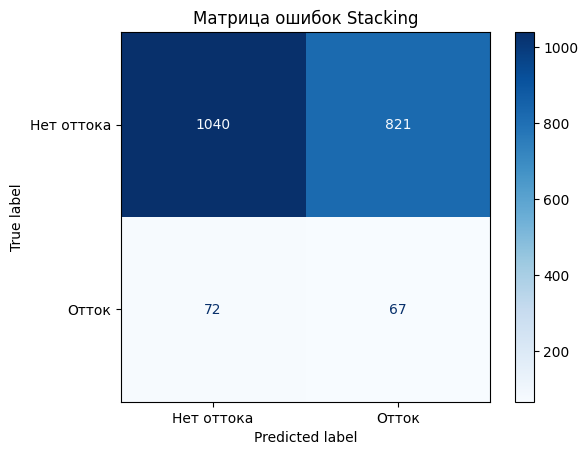

In [16]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Обучаю лучшую модель на обучающей и валидационной выборках
X_train_full = pd.concat([X_train, X_val])
y_train_full = pd.concat([y_train, y_val])

best_model = stacking_grid.best_estimator_
best_model.fit(X_train_full, y_train_full)

# Предсказания на тестовой выборке
y_test_pred = best_model.predict(X_test)
y_test_proba = best_model.predict_proba(X_test)[:, 1]

# Метрики
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_test_proba), 4
))

# Матрица ошибок
cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Нет оттока", "Отток"]
)

disp.plot(cmap="Blues")
plt.title("Матрица ошибок Stacking")
plt.show()

In [ ]:
'''На тестовой выборке модель Stacking получила F1 = 0.13 для класса оттока, Recall = 0.48 и ROC-AUC = 0.5241.
Модель находит почти половину клиентов с оттоком, но точность таких предсказаний остается низкой.
Результаты на тесте близки к результатам на валидации, поэтому существенного ухудшения качества не произошло.


Я дополнительно выведу числовые значения матрицы ошибок, чтобы зафиксировать количество правильных и ошибочных предсказаний модели.'''

In [17]:
print("Матрица ошибок:")
print(cm)

print("\nИтоговые метрики на тестовой выборке:")
test_results = pd.DataFrame({
    "Stacking": {
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1": f1_score(y_test, y_test_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_test_proba)
    }
}).T

display(test_results.round(4))

Матрица ошибок:
[[1040  821]
 [  72   67]]

Итоговые метрики на тестовой выборке:


,Accuracy,Precision,Recall,F1,ROC-AUC
Stacking,0.5535,0.0755,0.482,0.1305,0.5241


In [ ]:
'''В ходе работы я сравнила несколько ансамблевых алгоритмов классификации:
Bagging, Random Forest, Stacking, Gradient Boosting, LightGBM, XGBoost и CatBoost.
Также для сравнения использовала логистическую регрессию и дерево решений.
Для подбора гиперпараметров применяла GridSearchCV.
Качество моделей оценивала с помощью Accuracy, Precision, Recall, F1 и ROC-AUC.
Лучший результат на валидационной выборке показала модель
Stacking: F1 = 0.1333, Recall = 0.5036. Поэтому для итоговой проверки я выбрала именно эту модель.
На тестовой выборке Stacking показал Accuracy = 0.5535, Precision = 0.0755, Recall = 0.4820, F1 = 0.1305 и ROC-AUC = 0.5241.
Модель смогла обнаружить 67 из 139 клиентов с оттоком, однако количество ложноположительных
предсказаний оказалось высоким. Это говорит о том, что качество классификации пока остается невысоким.
В результате эксперимента я выяснила, что не все ансамблевые алгоритмы показывают лучшие результаты по сравнению
с одиночными моделями. В моем случае наиболее эффективной по F1 и Recall оказалась модель Stacking.'''